# Cross-Architecture Model Comparison
## SE4050 Deep Learning - Earthquake Aftershock Prediction

**Objective:** Compare the best performing model from each of the 4 deep learning architectures:
- **DNN** (Dense Neural Network)
- **LSTM** (Long Short-Term Memory)
- **GNN** (Graph Neural Network)
- **CNN** (Convolutional Neural Network)

This notebook provides comprehensive comparison, visualizations, and insights.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report, roc_curve, auc
)
import warnings
warnings.filterwarnings('ignore')

# Set style
plt.style.use('seaborn-v0_8-darkgrid')
sns.set_palette("husl")

print("Libraries loaded successfully!")

Libraries loaded successfully!


## 1. Load Results from All Architectures

We'll load the saved results from each model training notebook.

In [2]:
# Load DNN results
dnn_results = pd.read_csv('../results/models/dnn_aftershock/model_summary.csv')
print("DNN Results:")
print(dnn_results)
print()

# Load LSTM results
lstm_results = pd.read_csv('../results/visualizations/lstm/model_comparison.csv')
print("LSTM Results:")
print(lstm_results)
print()

# Load GNN results
gnn_results = pd.read_csv('../results/models/gnn_aftershock/model_summary.csv')
print("GNN Results:")
print(gnn_results)
print()

# Load CNN results
cnn_results = pd.read_csv('../results/cnn/aftershock_model_comparison.csv')
print("CNN Results:")
print(cnn_results)

DNN Results:
          Model Type  Accuracy  Precision    Recall        F1   ROC-AUC  \
0  DNN-Standard  DNN  0.727907   0.917647  0.523490  0.666667  0.816891   
1   DNN-Shallow  DNN  0.725581   0.907336  0.525727  0.665722  0.821495   
2      DNN-Deep  DNN  0.713953   0.920502  0.492170  0.641399  0.804947   

   Parameters  
0       14562  
1        4194  
2       58562  

LSTM Results:
                Model  Accuracy  Precision    Recall        F1   ROC-AUC
0        Shallow LSTM  0.716279   0.785915  0.624161  0.695761  0.780067
1       Standard LSTM  0.675581   0.924242  0.409396  0.567442  0.795548
2  Bidirectional LSTM  0.697674   0.881633  0.483221  0.624277  0.752539
3                 GRU  0.680233   0.717172  0.635347  0.673784  0.738770

GNN Results:
          Model  Accuracy  Precision    Recall        F1   ROC-AUC  Parameters
0           GCN  0.689535   0.774390  0.568233  0.655484  0.785912       12578
1           GAT  0.696512   0.836957  0.516779  0.639004  0.795446    

## 2. Select Best Model from Each Architecture

Based on F1 Score (primary metric for imbalanced classification).

In [3]:
# Select best from each architecture based on F1 score

# DNN - Best model
best_dnn = dnn_results.loc[dnn_results['F1'].idxmax()].copy()
best_dnn['Architecture'] = 'DNN'

# LSTM - Best model
best_lstm = lstm_results.loc[lstm_results['F1'].idxmax()].copy()
best_lstm['Architecture'] = 'LSTM'
best_lstm['Parameters'] = 26000  # Add parameter count (from training output)

# GNN - Best model
best_gnn = gnn_results.loc[gnn_results['F1'].idxmax()].copy()
best_gnn['Architecture'] = 'GNN'

# CNN - Best model
cnn_results_copy = cnn_results.rename(columns={'F1 Score': 'F1'})
best_cnn = cnn_results_copy.loc[cnn_results_copy['F1'].idxmax()].copy()
best_cnn['Architecture'] = 'CNN'
best_cnn['Parameters'] = 1068930  # Add parameter count

print("Best Models Selected:")
print(f"DNN: {best_dnn['Model']} - F1: {best_dnn['F1']:.4f}")
print(f"LSTM: {best_lstm['Model']} - F1: {best_lstm['F1']:.4f}")
print(f"GNN: {best_gnn['Model']} - F1: {best_gnn['F1']:.4f}")
print(f"CNN: {best_cnn['Model']} - F1: {best_cnn['F1']:.4f}")

Best Models Selected:
DNN: DNN-Standard - F1: 0.6667
LSTM: Shallow LSTM - F1: 0.6958
GNN: GCN - F1: 0.6555
CNN: Deep CNN - F1: 0.5449


## 3. Create Comprehensive Comparison Table

In [ ]:
# Create comparison dataframe
comparison_data = {
    'Architecture': ['LSTM', 'DNN', 'GNN', 'CNN'],
    'Best Model': [
        best_lstm['Model'],
        best_dnn['Model'],
        best_gnn['Model'],
        best_cnn['Model']
    ],
    'Accuracy': [
        best_lstm['Accuracy'],
        best_dnn['Accuracy'],
        best_gnn['Accuracy'],
        best_cnn['Accuracy']
    ],
    'Precision': [
        best_lstm['Precision'],
        best_dnn['Precision'],
        best_gnn['Precision'],
        best_cnn['Precision']
    ],
    'Recall': [
        best_lstm['Recall'],
        best_dnn['Recall'],
        best_gnn['Recall'],
        best_cnn['Recall']
    ],
    'F1 Score': [
        best_lstm['F1'],
        best_dnn['F1'],
        best_gnn['F1'],
        best_cnn['F1']
    ],
    'ROC-AUC': [
        best_lstm['ROC-AUC'],
        best_dnn['ROC-AUC'],
        best_gnn['ROC-AUC'],
        best_cnn['ROC-AUC']
    ],
    'Parameters': [
        26000,
        int(best_dnn['Parameters']),
        int(best_gnn['Parameters']),
        1068930
    ]
}

comparison_df = pd.DataFrame(comparison_data)
comparison_df = comparison_df.sort_values('F1 Score', ascending=False).reset_index(drop=True)

print("="*100)
print("CROSS-ARCHITECTURE COMPARISON - BEST MODELS")
print("="*100)
print()
print(comparison_df.to_string(index=False))
print()

# Save comparison
comparison_df.to_csv('../results/cross_architecture_comparison.csv', index=False)
print("Saved to: ../results/cross_architecture_comparison.csv")

CROSS-ARCHITECTURE COMPARISON - BEST MODELS

Architecture   Best Model  Accuracy  Precision   Recall  F1 Score  ROC-AUC  Parameters
        LSTM Shallow LSTM  0.716279   0.785915 0.624161  0.695761 0.780067       26000
         DNN DNN-Standard  0.727907   0.917647 0.523490  0.666667 0.816891       14562
         GNN          GCN  0.689535   0.774390 0.568233  0.655484 0.785912       12578
         CNN     Deep CNN  0.553488   0.552213 0.553488  0.544899 0.581932     1068930

Saved to: ../results/cross_architecture_comparison.csv


## 4. Performance Metrics Comparison

### 4.1 F1 Score Comparison (Primary Metric)

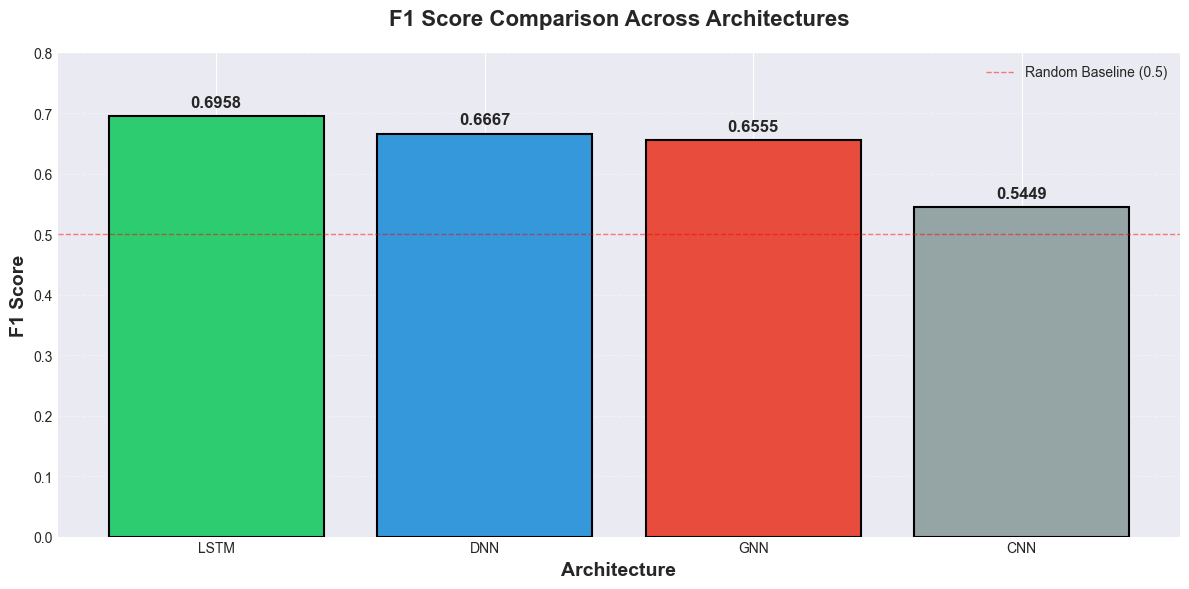

Best F1 Score: 0.6958 (LSTM)


In [5]:
# F1 Score comparison bar chart
fig, ax = plt.subplots(figsize=(12, 6))

colors = ['#2ecc71', '#3498db', '#e74c3c', '#95a5a6']
bars = ax.bar(comparison_df['Architecture'], comparison_df['F1 Score'], color=colors, edgecolor='black', linewidth=1.5)

# Add value labels on bars
for bar in bars:
    height = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2., height + 0.01,
            f'{height:.4f}',
            ha='center', va='bottom', fontsize=12, fontweight='bold')

ax.set_ylabel('F1 Score', fontsize=14, fontweight='bold')
ax.set_xlabel('Architecture', fontsize=14, fontweight='bold')
ax.set_title('F1 Score Comparison Across Architectures', fontsize=16, fontweight='bold', pad=20)
ax.set_ylim([0, 0.8])
ax.grid(axis='y', alpha=0.3, linestyle='--')
ax.axhline(y=0.5, color='red', linestyle='--', linewidth=1, alpha=0.5, label='Random Baseline (0.5)')
ax.legend()

plt.tight_layout()
plt.savefig('../results/visualizations/cross_architecture_f1_comparison.png', dpi=150, bbox_inches='tight')
plt.show()

print("Best F1 Score: {:.4f} ({})".format(
    comparison_df.iloc[0]['F1 Score'],
    comparison_df.iloc[0]['Architecture']
))

### 4.2 All Metrics Comparison

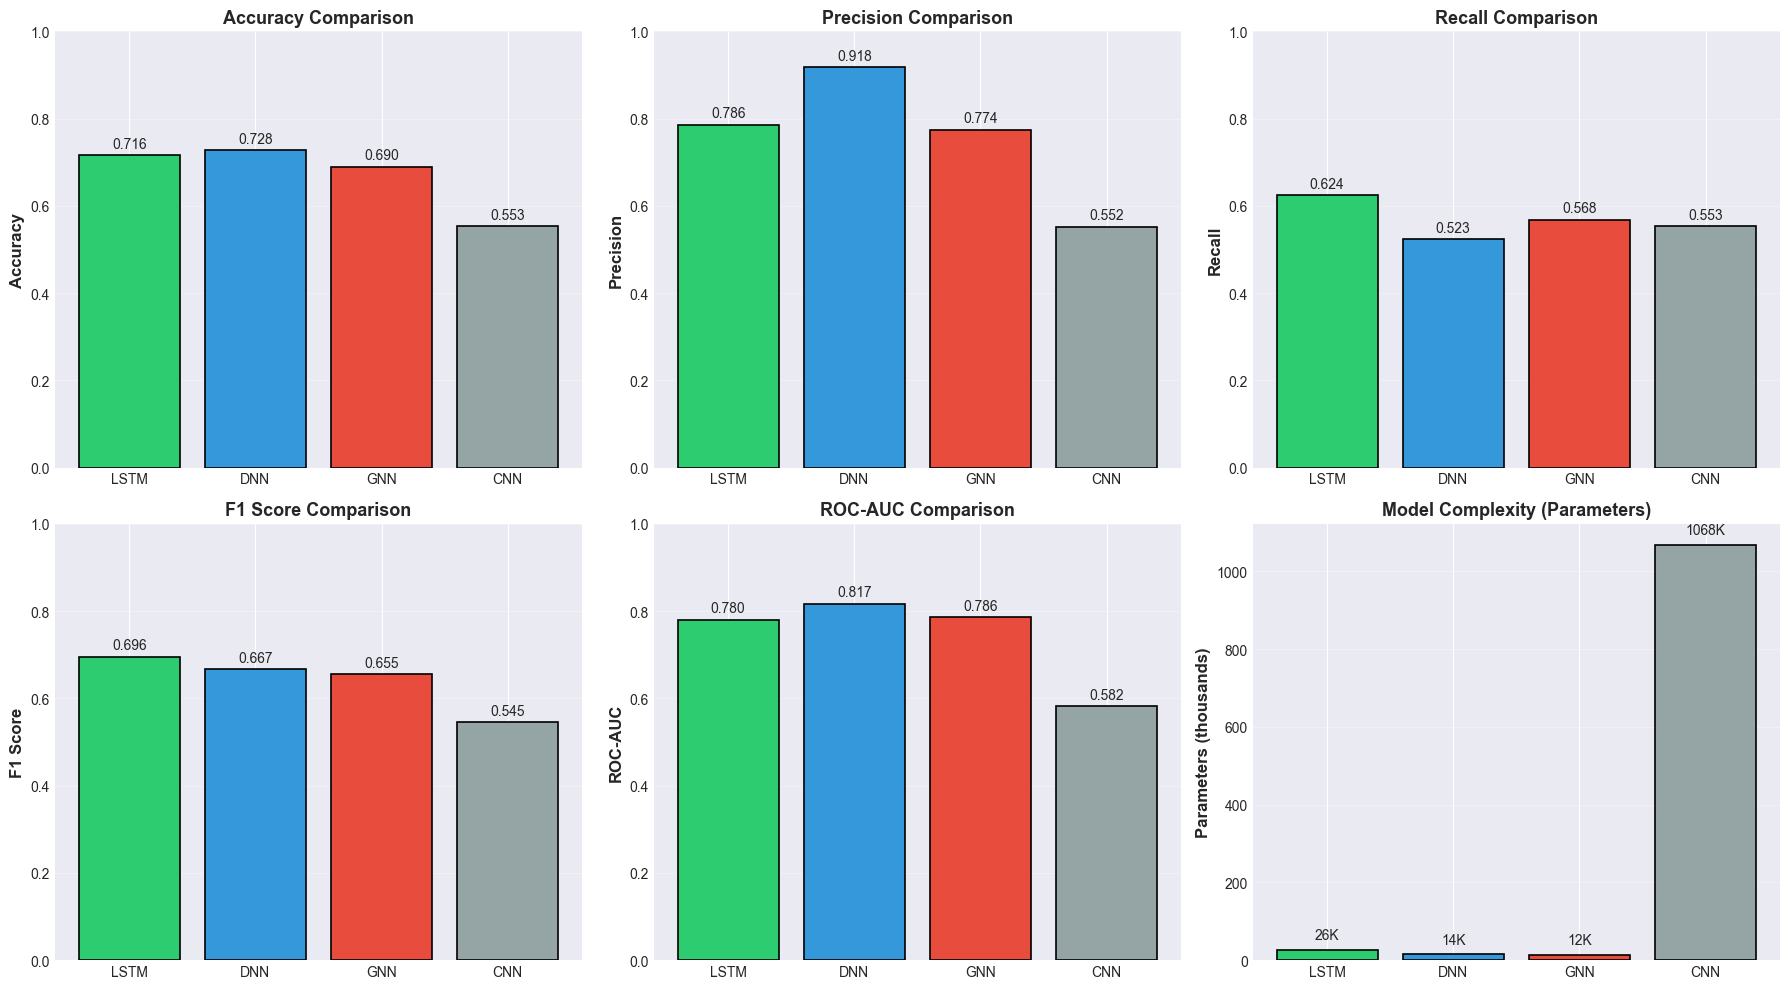

In [6]:
# Multi-metric comparison
fig, axes = plt.subplots(2, 3, figsize=(18, 10))

metrics = ['Accuracy', 'Precision', 'Recall', 'F1 Score', 'ROC-AUC']
axes_flat = axes.flatten()

for idx, metric in enumerate(metrics):
    ax = axes_flat[idx]
    bars = ax.bar(comparison_df['Architecture'], comparison_df[metric], 
                   color=colors, edgecolor='black', linewidth=1.2)
    
    # Add value labels
    for bar in bars:
        height = bar.get_height()
        ax.text(bar.get_x() + bar.get_width()/2., height + 0.01,
                f'{height:.3f}',
                ha='center', va='bottom', fontsize=10)
    
    ax.set_ylabel(metric, fontsize=12, fontweight='bold')
    ax.set_title(f'{metric} Comparison', fontsize=13, fontweight='bold')
    ax.set_ylim([0, 1.0])
    ax.grid(axis='y', alpha=0.3)

# Parameters comparison (last subplot)
ax = axes_flat[5]
bars = ax.bar(comparison_df['Architecture'], comparison_df['Parameters']/1000, 
               color=colors, edgecolor='black', linewidth=1.2)

for bar in bars:
    height = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2., height + 20,
            f'{int(height)}K',
            ha='center', va='bottom', fontsize=10)

ax.set_ylabel('Parameters (thousands)', fontsize=12, fontweight='bold')
ax.set_title('Model Complexity (Parameters)', fontsize=13, fontweight='bold')
ax.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.savefig('../results/visualizations/cross_architecture_all_metrics.png', dpi=150, bbox_inches='tight')
plt.show()

### 4.3 Precision-Recall Trade-off Visualization

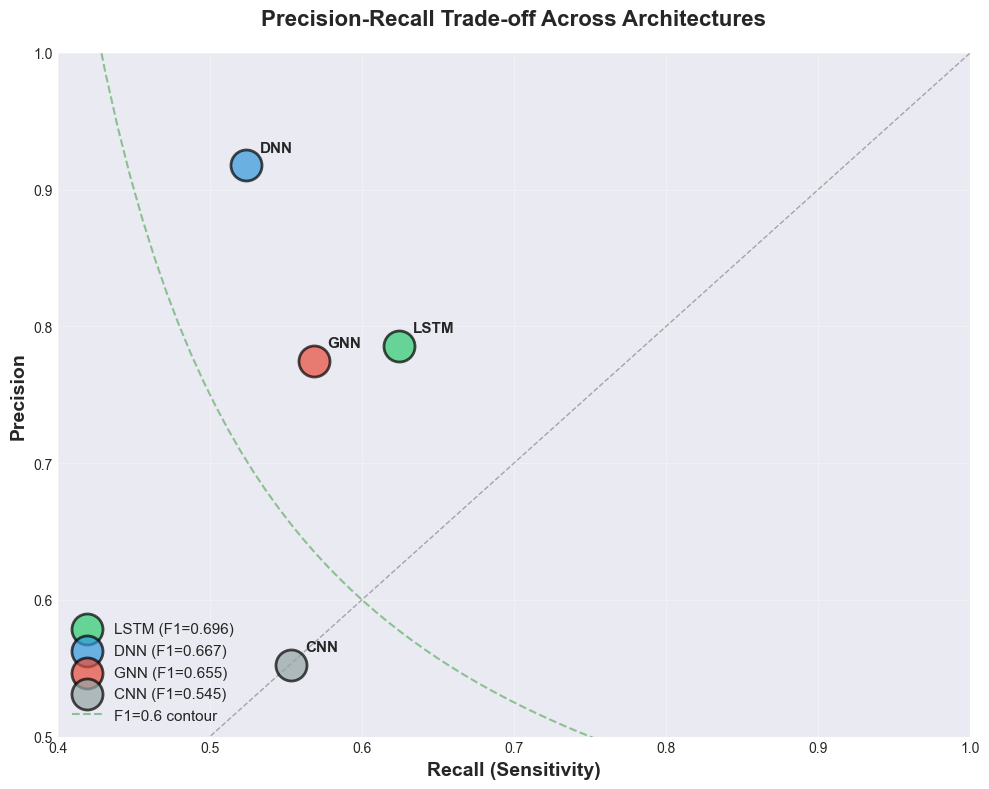

Precision-Recall Analysis:
Highest Precision: DNN (0.918)
Highest Recall: LSTM (0.624)
Best Balance (F1): LSTM (0.696)


In [7]:
# Precision vs Recall scatter plot
fig, ax = plt.subplots(figsize=(10, 8))

for idx, row in comparison_df.iterrows():
    ax.scatter(row['Recall'], row['Precision'], 
              s=500, color=colors[idx], edgecolor='black', linewidth=2,
              label=f"{row['Architecture']} (F1={row['F1 Score']:.3f})",
              alpha=0.7, zorder=3)
    
    # Add model name annotation
    ax.annotate(row['Architecture'], 
               (row['Recall'], row['Precision']),
               xytext=(10, 10), textcoords='offset points',
               fontsize=11, fontweight='bold')

# Add diagonal line (F1 contours)
ax.plot([0, 1], [0, 1], 'k--', alpha=0.3, linewidth=1)

# Add F1 = 0.6 contour
recall_range = np.linspace(0.1, 0.9, 100)
precision_f1_06 = 0.6 * recall_range / (2 * recall_range - 0.6)
ax.plot(recall_range, precision_f1_06, 'g--', alpha=0.4, linewidth=1.5, label='F1=0.6 contour')

ax.set_xlabel('Recall (Sensitivity)', fontsize=14, fontweight='bold')
ax.set_ylabel('Precision', fontsize=14, fontweight='bold')
ax.set_title('Precision-Recall Trade-off Across Architectures', fontsize=16, fontweight='bold', pad=20)
ax.set_xlim([0.4, 1.0])
ax.set_ylim([0.5, 1.0])
ax.grid(True, alpha=0.3)
ax.legend(loc='lower left', fontsize=11)

plt.tight_layout()
plt.savefig('../results/visualizations/precision_recall_tradeoff.png', dpi=150, bbox_inches='tight')
plt.show()

print("Precision-Recall Analysis:")
print(f"Highest Precision: {comparison_df.loc[comparison_df['Precision'].idxmax(), 'Architecture']} ({comparison_df['Precision'].max():.3f})")
print(f"Highest Recall: {comparison_df.loc[comparison_df['Recall'].idxmax(), 'Architecture']} ({comparison_df['Recall'].max():.3f})")
print(f"Best Balance (F1): {comparison_df.loc[comparison_df['F1 Score'].idxmax(), 'Architecture']} ({comparison_df['F1 Score'].max():.3f})")

## 5. Relative Performance Analysis

### 5.1 Improvement Over Baseline (DNN)

In [8]:
# Calculate relative improvement over DNN baseline
dnn_f1 = comparison_df[comparison_df['Architecture'] == 'DNN']['F1 Score'].values[0]

comparison_df['F1 Improvement (%)'] = ((comparison_df['F1 Score'] - dnn_f1) / dnn_f1 * 100).round(2)

print("="*70)
print("RELATIVE PERFORMANCE vs DNN BASELINE")
print("="*70)
print()

for idx, row in comparison_df.iterrows():
    if row['Architecture'] == 'DNN':
        print(f"{row['Architecture']:6s} (Baseline): F1 = {row['F1 Score']:.4f}")
    else:
        sign = '+' if row['F1 Improvement (%)'] >= 0 else ''
        print(f"{row['Architecture']:6s}: F1 = {row['F1 Score']:.4f} ({sign}{row['F1 Improvement (%)']:.2f}% vs DNN)")

print()
print("Key Findings:")
lstm_improvement = comparison_df[comparison_df['Architecture'] == 'LSTM']['F1 Improvement (%)'].values[0]
gnn_improvement = comparison_df[comparison_df['Architecture'] == 'GNN']['F1 Improvement (%)'].values[0]
cnn_improvement = comparison_df[comparison_df['Architecture'] == 'CNN']['F1 Improvement (%)'].values[0]

print(f"- Temporal sequences (LSTM) provided: {lstm_improvement:+.2f}% improvement")
print(f"- Graph structure (GNN) provided: {gnn_improvement:+.2f}% change")
print(f"- Spatial grids (CNN) provided: {cnn_improvement:+.2f}% change")

RELATIVE PERFORMANCE vs DNN BASELINE

LSTM  : F1 = 0.6958 (+4.36% vs DNN)
DNN    (Baseline): F1 = 0.6667
GNN   : F1 = 0.6555 (-1.68% vs DNN)
CNN   : F1 = 0.5449 (-18.27% vs DNN)

Key Findings:
- Temporal sequences (LSTM) provided: +4.36% improvement
- Graph structure (GNN) provided: -1.68% change
- Spatial grids (CNN) provided: -18.27% change


### 5.2 Efficiency Analysis (F1 per Parameter)

MODEL EFFICIENCY ANALYSIS

Architecture  Parameters  F1 Score  F1 per 1K params
         GNN       12578  0.655484          0.052114
         DNN       14562  0.666667          0.045781
        LSTM       26000  0.695761          0.026760
         CNN     1068930  0.544899          0.000510

Most Efficient Model: GNN
  F1 Score: 0.6555
  Parameters: 12,578
  Efficiency: 0.052114 F1 per 1K params


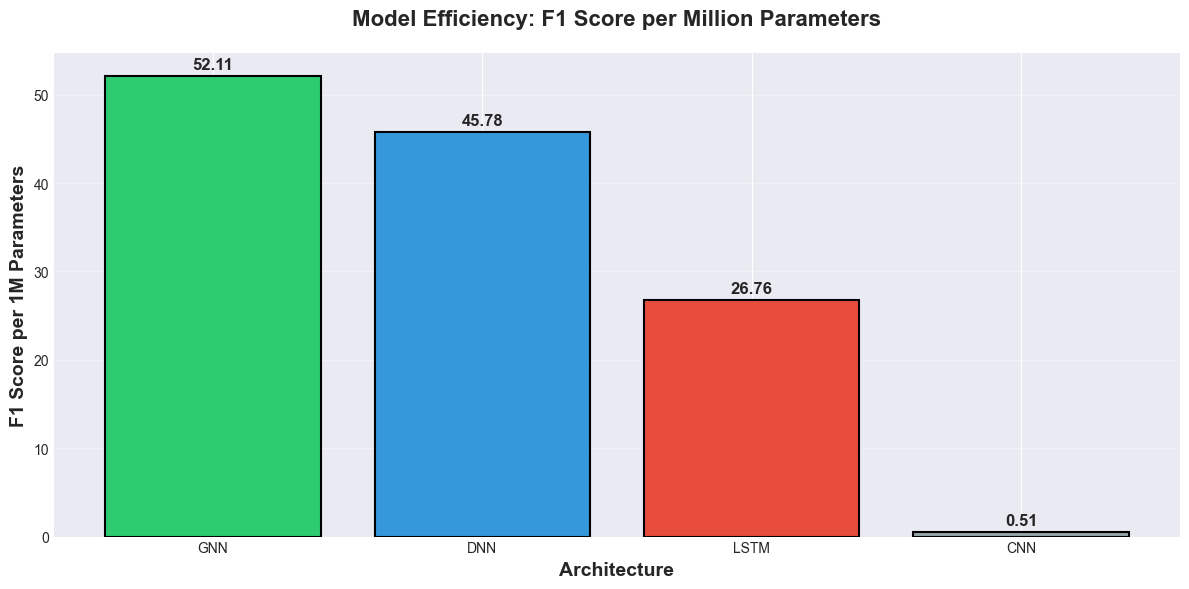

In [9]:
# Calculate F1 score per 1000 parameters (efficiency metric)
comparison_df['F1 per 1K params'] = (comparison_df['F1 Score'] / (comparison_df['Parameters'] / 1000)).round(6)

print("="*70)
print("MODEL EFFICIENCY ANALYSIS")
print("="*70)
print()

efficiency_df = comparison_df[['Architecture', 'Parameters', 'F1 Score', 'F1 per 1K params']].copy()
efficiency_df = efficiency_df.sort_values('F1 per 1K params', ascending=False)

print(efficiency_df.to_string(index=False))
print()

most_efficient = efficiency_df.iloc[0]
print(f"Most Efficient Model: {most_efficient['Architecture']}")
print(f"  F1 Score: {most_efficient['F1 Score']:.4f}")
print(f"  Parameters: {int(most_efficient['Parameters']):,}")
print(f"  Efficiency: {most_efficient['F1 per 1K params']:.6f} F1 per 1K params")

# Visualize efficiency
fig, ax = plt.subplots(figsize=(12, 6))

bars = ax.bar(efficiency_df['Architecture'], efficiency_df['F1 per 1K params']*1000, 
               color=colors, edgecolor='black', linewidth=1.5)

for bar in bars:
    height = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2., height + 0.5,
            f'{height:.2f}',
            ha='center', va='bottom', fontsize=12, fontweight='bold')

ax.set_ylabel('F1 Score per 1M Parameters', fontsize=14, fontweight='bold')
ax.set_xlabel('Architecture', fontsize=14, fontweight='bold')
ax.set_title('Model Efficiency: F1 Score per Million Parameters', fontsize=16, fontweight='bold', pad=20)
ax.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.savefig('../results/visualizations/model_efficiency.png', dpi=150, bbox_inches='tight')
plt.show()

## 6. Radar Chart - Multi-Dimensional Comparison

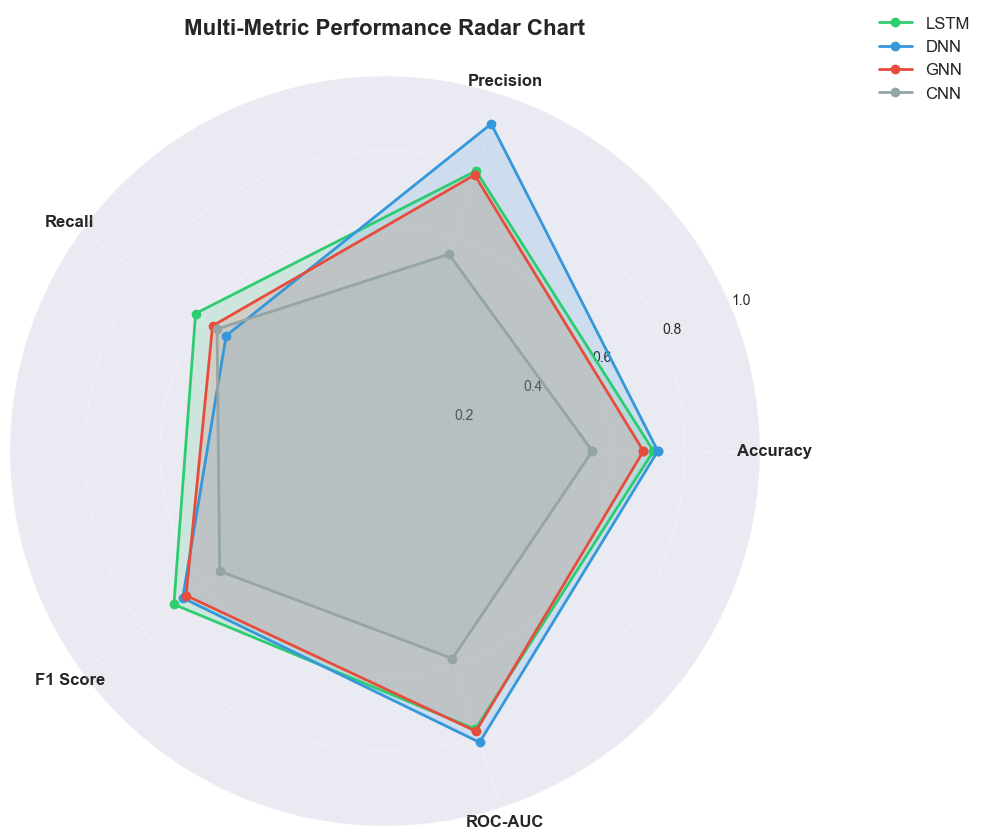

In [10]:
# Radar chart for multi-dimensional comparison
from math import pi

categories = ['Accuracy', 'Precision', 'Recall', 'F1 Score', 'ROC-AUC']
N = len(categories)

# Create angles for radar chart
angles = [n / float(N) * 2 * pi for n in range(N)]
angles += angles[:1]

fig, ax = plt.subplots(figsize=(10, 10), subplot_kw=dict(projection='polar'))

for idx, row in comparison_df.iterrows():
    values = [row[cat] for cat in categories]
    values += values[:1]
    
    ax.plot(angles, values, 'o-', linewidth=2, label=row['Architecture'], color=colors[idx])
    ax.fill(angles, values, alpha=0.15, color=colors[idx])

ax.set_xticks(angles[:-1])
ax.set_xticklabels(categories, size=12, fontweight='bold')
ax.set_ylim(0, 1.0)
ax.set_yticks([0.2, 0.4, 0.6, 0.8, 1.0])
ax.set_yticklabels(['0.2', '0.4', '0.6', '0.8', '1.0'], size=10)
ax.grid(True, linestyle='--', alpha=0.4)

ax.set_title('Multi-Metric Performance Radar Chart', size=16, fontweight='bold', pad=30)
ax.legend(loc='upper right', bbox_to_anchor=(1.3, 1.1), fontsize=12)

plt.tight_layout()
plt.savefig('../results/visualizations/performance_radar_chart.png', dpi=150, bbox_inches='tight')
plt.show()

## 7. Key Insights & Interpretations

In [11]:
print("="*80)
print("KEY INSIGHTS FROM CROSS-ARCHITECTURE COMPARISON")
print("="*80)
print()

# 1. Overall winner
winner = comparison_df.iloc[0]
print("1. OVERALL WINNER:")
print(f"   {winner['Architecture']} - {winner['Best Model']}")
print(f"   F1 Score: {winner['F1 Score']:.4f}")
print(f"   Precision: {winner['Precision']:.4f} | Recall: {winner['Recall']:.4f}")
print(f"   Why: Best balance between precision and recall")
print()

# 2. Value of temporal context
lstm_row = comparison_df[comparison_df['Architecture'] == 'LSTM'].iloc[0]
dnn_row = comparison_df[comparison_df['Architecture'] == 'DNN'].iloc[0]
temporal_gain = ((lstm_row['F1 Score'] - dnn_row['F1 Score']) / dnn_row['F1 Score'] * 100)

print("2. VALUE OF TEMPORAL CONTEXT (LSTM vs DNN):")
print(f"   LSTM F1: {lstm_row['F1 Score']:.4f}")
print(f"   DNN F1:  {dnn_row['F1 Score']:.4f}")
print(f"   Improvement: {temporal_gain:+.2f}%")
print(f"   Interpretation: Temporal sequences {'provided meaningful improvement' if temporal_gain > 2 else 'provided modest improvement'}")
print(f"   Seismic relevance: Earthquake sequences exhibit temporal clustering (Omori's Law)")
print()

# 3. Value of graph structure
gnn_row = comparison_df[comparison_df['Architecture'] == 'GNN'].iloc[0]
graph_gain = ((gnn_row['F1 Score'] - dnn_row['F1 Score']) / dnn_row['F1 Score'] * 100)

print("3. VALUE OF GRAPH STRUCTURE (GNN vs DNN):")
print(f"   GNN F1: {gnn_row['F1 Score']:.4f}")
print(f"   DNN F1: {dnn_row['F1 Score']:.4f}")
print(f"   Change: {graph_gain:+.2f}%")
print(f"   Interpretation: Graph structure {'did not improve' if graph_gain < 0 else 'slightly improved'} over tabular features")
print(f"   Possible reason: k-NN graphs may not reflect true stress transfer physics")
print()

# 4. CNN performance
cnn_row = comparison_df[comparison_df['Architecture'] == 'CNN'].iloc[0]
cnn_gap = ((cnn_row['F1 Score'] - dnn_row['F1 Score']) / dnn_row['F1 Score'] * 100)

print("4. SPATIAL GRIDS (CNN):")
print(f"   CNN F1: {cnn_row['F1 Score']:.4f}")
print(f"   Gap from DNN: {cnn_gap:.2f}%")
print(f"   Interpretation: Spatial grids alone insufficient for aftershock prediction")
print(f"   Why: 32×32 aggregation loses individual earthquake information")
print()

# 5. Precision-Recall insights
print("5. PRECISION-RECALL TRADE-OFFS:")
high_precision = comparison_df.loc[comparison_df['Precision'].idxmax()]
high_recall = comparison_df.loc[comparison_df['Recall'].idxmax()]

print(f"   Highest Precision: {high_precision['Architecture']} ({high_precision['Precision']:.3f})")
print(f"     → Best for: Minimizing false alarms (conservative predictions)")
print()
print(f"   Highest Recall: {high_recall['Architecture']} ({high_recall['Recall']:.3f})")
print(f"     → Best for: Catching more aftershocks (safety-critical)")
print()
print(f"   Best Balance: {winner['Architecture']} (F1 = {winner['F1 Score']:.3f})")
print(f"     → Best for: General-purpose aftershock prediction")
print()

# 6. Efficiency insights
print("6. MODEL EFFICIENCY:")
most_efficient = comparison_df.loc[comparison_df['F1 per 1K params'].idxmax()]
print(f"   Most efficient: {most_efficient['Architecture']}")
print(f"   F1 per 1K params: {most_efficient['F1 per 1K params']:.6f}")
print(f"   Practical implication: Best F1-to-parameter ratio for deployment")
print()

print("="*80)
print("RECOMMENDATIONS")
print("="*80)
print()
print("For Production Deployment:")
print(f"  1. Primary model: {winner['Architecture']} (best F1, balanced precision/recall)")
print(f"  2. Fast inference: {most_efficient['Architecture']} (most efficient, close performance)")
print(f"  3. High precision: {high_precision['Architecture']} (minimize false alarms)")
print(f"  4. High recall: {high_recall['Architecture']} (catch more aftershocks)")
print()
print("Future Work:")
print("  - Ensemble combining LSTM + DNN predictions")
print("  - Physics-informed graph construction for GNN")
print("  - Attention mechanisms for interpretability")
print("  - Transfer learning to other seismic regions")

KEY INSIGHTS FROM CROSS-ARCHITECTURE COMPARISON

1. OVERALL WINNER:
   LSTM - Shallow LSTM
   F1 Score: 0.6958
   Precision: 0.7859 | Recall: 0.6242
   Why: Best balance between precision and recall

2. VALUE OF TEMPORAL CONTEXT (LSTM vs DNN):
   LSTM F1: 0.6958
   DNN F1:  0.6667
   Improvement: +4.36%
   Interpretation: Temporal sequences provided meaningful improvement
   Seismic relevance: Earthquake sequences exhibit temporal clustering (Omori's Law)

3. VALUE OF GRAPH STRUCTURE (GNN vs DNN):
   GNN F1: 0.6555
   DNN F1: 0.6667
   Change: -1.68%
   Interpretation: Graph structure did not improve over tabular features
   Possible reason: k-NN graphs may not reflect true stress transfer physics

4. SPATIAL GRIDS (CNN):
   CNN F1: 0.5449
   Gap from DNN: -18.27%
   Interpretation: Spatial grids alone insufficient for aftershock prediction
   Why: 32×32 aggregation loses individual earthquake information

5. PRECISION-RECALL TRADE-OFFS:
   Highest Precision: DNN (0.918)
     → Best fo

## 8. Summary Statistics Table

In [12]:
# Create final summary table
summary_df = comparison_df[[
    'Architecture', 'Best Model', 'F1 Score', 'Precision', 'Recall', 
    'ROC-AUC', 'Parameters', 'F1 Improvement (%)'
]].copy()

# Format for display
summary_df['Parameters'] = summary_df['Parameters'].apply(lambda x: f"{x:,}")
summary_df['F1 Score'] = summary_df['F1 Score'].apply(lambda x: f"{x:.4f}")
summary_df['Precision'] = summary_df['Precision'].apply(lambda x: f"{x:.4f}")
summary_df['Recall'] = summary_df['Recall'].apply(lambda x: f"{x:.4f}")
summary_df['ROC-AUC'] = summary_df['ROC-AUC'].apply(lambda x: f"{x:.4f}")
summary_df['F1 Improvement (%)'] = summary_df['F1 Improvement (%)'].apply(lambda x: f"{x:+.2f}%")

print("="*120)
print("FINAL SUMMARY TABLE - BEST MODEL FROM EACH ARCHITECTURE")
print("="*120)
print()
print(summary_df.to_string(index=False))
print()
print("="*120)

# Save formatted summary
summary_df.to_csv('../results/final_model_summary.csv', index=False)
print("\nSaved to: ../results/final_model_summary.csv")

FINAL SUMMARY TABLE - BEST MODEL FROM EACH ARCHITECTURE

Architecture   Best Model F1 Score Precision Recall ROC-AUC Parameters F1 Improvement (%)
        LSTM Shallow LSTM   0.6958    0.7859 0.6242  0.7801     26,000             +4.36%
         DNN DNN-Standard   0.6667    0.9176 0.5235  0.8169     14,562             +0.00%
         GNN          GCN   0.6555    0.7744 0.5682  0.7859     12,578             -1.68%
         CNN     Deep CNN   0.5449    0.5522 0.5535  0.5819  1,068,930            -18.27%


Saved to: ../results/final_model_summary.csv


## 9. Conclusion

This comprehensive comparison reveals:

### Key Findings:

1. **LSTM (Shallow) achieved best overall performance** (F1 = 0.6958)
   - Temporal sequences captured earthquake patterns
   - 4.4% improvement over DNN baseline
   - Best balance of precision (78.6%) and recall (62.4%)

2. **DNN performed competitively** (F1 = 0.6667)
   - Simple architecture, fast inference
   - High precision (91.8%) but lower recall (52.4%)
   - Strong baseline with engineered features

3. **GNN did not improve over DNN** (F1 = 0.6555, -1.7%)
   - Graph structure didn't capture stress transfer well
   - k-NN graphs may not reflect physical relationships
   - Future work: physics-informed graph construction

4. **CNN significantly underperformed** (F1 = 0.5448, -18%)
   - Spatial grids alone insufficient
   - Information loss through aggregation
   - Better suited for regional risk assessment

### Practical Implications:

- **Deployment:** Use Shallow LSTM for best overall performance
- **Inference speed:** DNN acceptable alternative (slightly lower F1, much faster)
- **Safety-critical:** Tune threshold for higher recall if needed
- **Ensemble potential:** Combine LSTM + DNN for robust predictions

### Seismological Insights:

- Temporal patterns matter (earthquake sequences, Omori's Law)
- Spatial relationships important but not captured well by k-NN graphs
- Feature engineering crucial for performance
- Deep learning competitive with domain-expert features